# Limitation 5 — The blend

**Inside about one FWHM the two profiles of a window overlap. The along-scan position of the fainter one is no longer a well-posed measurement: its error grows, and at low signal-to-noise the likelihood of a window has more than one basin. Every atom inherits that, each in its own way.**

Every limitation notebook has the same four parts. **The premise** states
what the atoms assume and shows the case that breaks it. Then **one section
per atom**, always in the same order, the two images of the windows, the map
of detections, the joint fit, each answering three questions: what does this
atom assume here, what does it return in this case, and does it warn you.
**The summary table** closes with the same columns every time: atom, effect,
alarm, remedy.

The case of this page: a pair at 40 or 50 mas, 0.4 to 0.5 FWHM, with flux ratio 0.2 at S/N 100 (noise σ 10 per sample) and flux ratio 0.1 at S/N 33 (σ 30); the control pair at 200 mas for comparison.

| block | task | calls | paper |
|---|---|---|---|
| 1 | the premise: one blended window and its profiled likelihood along the scan | `sim.simulate_window`, `ins.render_window`, `joint.loglike_profiled` | Sect. 2.1, Eqs. 1–3; Sect. 6.1, Fig. 5; App. B.1 |
| 2 | the two images of a blended pair and of the control pair | `radon.filtered_backprojection`, `radon.faststack` | App. C.2, Eq. C.3 |
| 3 | 200 window fits per case: what the map of detections receives | `joint.loglike_profiled` (through the page's `window_fit`) | Sect. 2.2; App. B.1 |
| 4 | the Fisher bound against the separation; the joint fit from two seeds | `joint.joint_fisher`, `joint.joint_covariance`, `joint.fit_joint` | Sect. 6.1, Fig. 5; App. B.2; Sect. 4.3, Eq. 18 |

Every scanlib call carries the name of its module (`joint.fit_joint`); the first code cell lists the modules.

**The series.** The three images and the fit are in [`../00_three_images_and_fit.ipynb`](../00_three_images_and_fit.ipynb). The limitations: [1 — the finite window](01_finite_window.ipynb), [2 — the scan law](02_scan_law.ipynb), [3 — one line, two lines, three](03_few_lines.ipynb), [4 — a scene that moves](04_motion.ipynb), this page, [6 — errors of the model, and the noise](06_model_errors.ipynb).

**Symbols and units** are defined once for the package and every notebook in [`docs/conventions.md`](../../../docs/conventions.md). This page uses ψ, η, ρ in FWHM, q, σ and S/N, σ_η and the detections, the two images, the profiled likelihood, the Fisher σ (the Cramér–Rao bound), and χ².

In [1]:
# the imports: numpy, matplotlib, and the scanlib modules; every scanlib call below carries its module's name
import numpy as np
import matplotlib.pyplot as plt

from scanlib import instrument as ins      # the instrument: sampling, LSF, the along-scan projection (Eq. 9)
from scanlib import simulation as sim      # synthetic scenes and their windows
from scanlib import backprojection as bp   # the triangulation map and its peak
from scanlib import radon                  # the inverse Radon transform and faststack
from scanlib import joint                  # the joint fit of all windows, and its helpers

In [2]:
# the paper's figure style: font 10, ticks 9 and inward, thin axes; grays first, one accent
plt.rcParams.update({"font.size": 10.0, "axes.linewidth": 0.5, "xtick.labelsize": 9.0, "ytick.labelsize": 9.0,
                     "xtick.direction": "in", "ytick.direction": "in", "legend.frameon": False, "legend.fontsize": 7.5})
ACCENT = "tomato"                                          # the one accent
# the labels of the two sky axes
EAST = r"$\Delta\alpha^{*}$  [mas]   (East $\leftarrow$)"
NORTH = r"$\Delta\delta$  [mas]"


def letter(ax, label, text=""):
    """Write a panel's letter, bold, inside the panel's top-left corner, and a few words after it.

    Inputs
        ax      the panel (a matplotlib Axes)
        label   the panel's letter, for example "a"
        text    the words after the letter (default: none)
    Returns nothing: the letter and the words are drawn on ax, on a white box that dims what is under them."""
    white_box = dict(fc="white", ec="none", pad=1.0, alpha=0.8)
    ax.text(0.04, 0.96, rf"$\bf{{({label})}}$ " + text, transform=ax.transAxes, va="top", ha="left", fontsize=9,
            bbox=white_box)

In [3]:
# the toy instrument, the noise, the pair's position angle and fluxes, the two sets of scan directions, and the
# sky grid of every image
FWHM = 100.0                                 # the LSF's full width at half maximum [mas]
# The instrument, defined once: 18 samples 59 mas apart, a Gaussian LSF of
# that FWHM, and the trial positions of the per-window reduction.
inst = ins.Instrument.gaussian(fwhm_mas=FWHM, pitch_mas=59.0, n_samples=18)
grid = inst.sample_grid_mas                  # sample centers along the scan [mas]
pitch = grid[1] - grid[0]                    # the distance between two neighboring samples: 59 mas
sigma_lsf = FWHM / (2.0 * np.sqrt(2.0 * np.log(2.0)))   # LSF sigma [mas], for the formulas
sigma_noise = 10.0                           # the noise sigma of one sample; the primary's total flux is 100 sigma
pa = np.deg2rad(110.0)                       # the pair's position angle [rad], counter-clockwise from north
flux = np.array([1000.0, 200.0])             # the fluxes of the primary and of the companion, in the windows' units
EVEN = np.linspace(0.0, np.pi, 80, endpoint=False) + 0.01     # 80 even directions [rad]
# ref: the reference cases of the package's tests, a table from a case's name to its array; two of its inputs
# are used here
ref = np.load("../../../tests/reference/reference_cases.npz")
GAIA = ref["static_pair/inputs/psi"]                           # the Gaia forecast's 40 scan angles [rad]
GAIA_TAU = ref["moving_pair/inputs/tau"]                       # and epochs [yr]
half = 400.0                                 # the sky grid of every image: half the side of the square [mas]
step = 4.0                                   # and the size of one pixel [mas]
# degrees of freedom of a static two-source fit on 80 windows: 80 x 18 samples, minus the companion's two
# coordinates and the two fluxes
DOF = EVEN.size * grid.size - 4

In [4]:
# helper: the companion's sky offset at a separation on the pair axis
def pair(rho):
    """The companion's sky offset at a separation on the pair axis (the direction of position angle pa).

    Inputs
        rho   the companion's separation from the primary [mas]
    Returns
        the companion's (dra*, ddec) [mas] from the primary, an array of two numbers"""
    pair_axis = np.array([np.sin(pa), np.cos(pa)])            # the unit vector of the pair axis, (dra*, ddec)
    return rho * pair_axis

In [5]:
# helper: the windows of a scene, noise-free or noisy (ins.render_window, sim.simulate_window)
def windows_of(theta, psi, flux=flux, tau=None, rng=None, present=None, eta0=None, inst=inst):
    """The windows of a scene, one per scan: noise-free (a formula), or with one draw of noise each.

    Inputs
        theta     the companions' parameters, one flat array: (dra*, ddec) [mas] per companion for a static scene,
                  (dra*, ddec [mas], mu_alpha*, mu_delta [mas/yr]) per companion for a moving one. The primary is
                  at the origin and has no entry
        psi       the scan angle of each of the J windows [rad]
        flux      the flux of each of the K sources, in the windows' units, the primary first
        tau       the epoch of each window [yr] for a moving scene (None: a static scene)
        rng       the random generator of the noise, of sigma_noise per sample (None: noise-free windows)
        present   J rows of K booleans: which source is in which window (None: every source in every window)
        eta0      the zero point of each window [mas] (None: every zero point is 0)
        inst      the instrument that renders the windows (default: the page's instrument)
    Returns
        the windows, an array of J rows of N samples, flux per sample"""
    # step 1, the along-scan position of every source in every window [mas]: one row per window, one column per
    # source, the primary first. Each window's zero point is subtracted from its row; [:, None] turns the J zero
    # points into a column, so that row j gets eta0[j]
    eta = joint.scene_positions_al(theta, psi, tau)
    if eta0 is not None:
        eta = eta - np.asarray(eta0)[:, None]

    # step 2, one window per scan; j counts the windows
    windows = []
    for j, eta_j in enumerate(eta):
        # the fluxes in window j: present[j] holds one True or False per source, and a source that is not in
        # the window gets flux 0
        if present is None:
            flux_j = flux
        else:
            flux_j = flux * present[j]
        # the samples of window j: the noise-free model, or the model plus one draw of noise from rng
        if rng is None:
            window = ins.render_window(eta_j, flux_j, inst)
        else:
            window = sim.simulate_window(eta_j, flux_j, inst, rng, sigma_noise)
        windows.append(window)
    return np.array(windows)

In [6]:
# helper, a stand-in for the per-window reduction: the Fisher error of each companion's position in one window
def sigma_eta(eta, flux=flux, sigma_noise=sigma_noise):
    """The Fisher error of each companion's along-scan position in one window, with every flux free. It is a
    formula, not a fit: it stands in for the error that the per-window reduction would report.

    Inputs
        eta           the along-scan position of each of the K sources in the window [mas], the primary first
        flux          the flux of each of the K sources, in the windows' units, the primary first
        sigma_noise   the noise sigma of one sample, in the windows' units
    Returns
        the 1-sigma error of each companion's position [mas], K - 1 numbers (the primary's position is not a
        parameter); every one is infinite where the Fisher matrix is singular"""
    # step 1, the model of the window. columns[:, k] is the window of source k alone at flux 1, one number per
    # sample; derivatives[:, k] is the derivative of that column with respect to the position of source k [1/mas]
    columns = inst.design_columns(eta)
    derivatives = inst.design_jacobian(eta)

    # step 2, the derivative of the window with respect to every parameter, one column each: first the
    # companions' positions ([:, 1:] omits the primary's column and flux[1:] the primary's flux), then the K fluxes
    jacobian = np.column_stack([derivatives[:, 1:] * flux[1:], columns])

    # step 3, the Fisher matrix for Gaussian noise of known sigma. Where its condition number is above 1e12 it
    # cannot be inverted safely: the companions' positions are then not measured in this window
    fisher = jacobian.T @ jacobian / sigma_noise ** 2
    n_companions = eta.size - 1
    if np.linalg.cond(fisher) > 1e12:
        return np.full(n_companions, np.inf)

    # step 4, the errors: the square roots of the diagonal of the inverse. [:n_companions] keeps the positions'
    # entries and omits the fluxes'
    covariance = np.linalg.inv(fisher)
    return np.sqrt(np.diag(covariance)[:n_companions])

In [7]:
# helper, the stand-in's detections: the truth plus one draw of that error, where the error is below 30 mas
def detections(theta, psi, flux=flux, tau=None, sigma_max=30.0, rng=None, present=None):
    """The teaching detections of a scene, a stand-in for the per-window reduction: no window is simulated and no
    window is fitted. A detection is a companion's true along-scan position in a window plus one Gaussian draw of
    its Fisher error there (sigma_eta, at the page's noise sigma_noise).

    Inputs
        theta       the companions' parameters, one flat array, as in windows_of
        psi         the scan angle of each of the J windows [rad]
        flux        the flux of each of the K sources, in the windows' units, the primary first
        tau         the epoch of each window [yr] for a moving scene (None: a static scene)
        sigma_max   a companion gives a detection in a window only where its Fisher error is finite and at most
                    this [mas]
        rng         the random generator of the draws (None: a new generator of seed 8 at every call)
        present     J rows of K booleans: which source is in which window (None: every source in every window);
                    a companion gives no detection in a window that it is not in
    Returns three arrays, one entry per detection
        psi     the scan angle of the detection's window [rad]
        eta     the detected along-scan position [mas]: the truth plus the draw
        sigma   the 1-sigma error of that position [mas]"""
    # step 1, the generator of the detections' errors. The default is a new generator of seed 8 at every call,
    # so two calls for the same scene give the same draws (why 8: not stated)
    if rng is None:
        rng_detections = np.random.default_rng(8)
    else:
        rng_detections = rng

    # step 2, the true along-scan position of every source in every window [mas]: row j is window j, column 0
    # the primary
    eta_true = joint.scene_positions_al(theta, psi, tau)

    # step 3, one detection per window and companion that passes the two tests. j counts the windows; c counts
    # the sources of a window from 1, because source 0 is the primary and gives no detection
    detected_psi = []
    detected_eta = []
    detected_sigma = []
    for j, psi_j in enumerate(psi):
        eta_j = eta_true[j]
        sigma_j = sigma_eta(eta_j, flux)                       # the Fisher error of each companion in window j
        for c in range(1, eta_j.size):
            sigma = sigma_j[c - 1]                             # sigma_j has no entry for the primary
            if present is not None and not present[j, c]:
                continue
            if np.isfinite(sigma) and sigma <= sigma_max:
                error_draw = rng_detections.normal(0.0, sigma)
                detected_psi.append(psi_j)
                detected_eta.append(eta_j[c] + error_draw)
                detected_sigma.append(sigma)
    return np.array(detected_psi), np.array(detected_eta), np.array(detected_sigma)

In [8]:
# helper: the points of a covariance ellipse
def ellipse(cov, center, n_sigma=1.0):
    """The outline of a covariance ellipse on the sky, as points to plot.

    Inputs
        cov       the 2 x 2 covariance of a position (dra*, ddec) [mas^2]
        center    the center of the ellipse, (dra*, ddec) [mas]
        n_sigma   the size of the ellipse, its Mahalanobis radius (1: the 1-sigma ellipse)
    Returns
        200 points around the ellipse, one row (dra*, ddec) [mas] per point; the last point repeats the first"""
    # step 1, the ellipse's axes: the eigenvalues are the variances along them [mas^2], the columns of
    # eigenvectors are their directions
    eigenvalues, eigenvectors = np.linalg.eigh(cov)

    # step 2, the unit circle at 200 angles around the full turn: row 0 holds the cosines, row 1 the sines
    angles = np.linspace(0, 2 * np.pi, 200)
    unit_circle = np.vstack([np.cos(angles), np.sin(angles)])

    # step 3, the circle stretched to the ellipse's semi-axes ([:, None] makes them a column: one factor per
    # row of the circle), turned to the axes' directions, and moved to the center. .T gives one row per point
    semi_axes = n_sigma * np.sqrt(eigenvalues)[:, None]
    stretched = semi_axes * unit_circle
    turned = eigenvectors @ stretched
    return turned.T + center

In [9]:
# helper: draw one sky image or map, east to the left, with the sources marked
def show(ax, image, axis, title, marks=None, **imshow_options):
    """Draw one sky image or map, east to the left, with the sources marked by plus signs.

    Inputs
        ax               the panel (a matplotlib Axes)
        image            the image or the map, M rows of M pixels: the rows are ddec, the columns dra*
        axis             the sky coordinate of the M rows, and of the M columns [mas]
        title            the panel's title
        marks            the sources to mark, one row (dra*, ddec) [mas] each (None: the primary at the origin and
                         the companion of this page, the global theta)
        imshow_options   keywords for ax.imshow, for example vmax, the value drawn black
    Returns
        the drawn image (matplotlib's AxesImage)"""
    # step 1, the defaults of the picture, used where the call names no other: white at 0 and black at the
    # highest value, and every pixel drawn as it is (no smoothing)
    imshow_options.setdefault("cmap", "gray_r")
    imshow_options.setdefault("vmin", 0.0)
    imshow_options.setdefault("interpolation", "nearest")

    # step 2, the picture: row 0 at the bottom (north up); axis[0] and axis[-1] are the first and the last
    # coordinate, given as the picture's left and right, and bottom and top
    extent = (axis[0], axis[-1], axis[0], axis[-1])
    drawn_image = ax.imshow(image, origin="lower", extent=extent, **imshow_options)

    # step 3, the plus signs: column 0 of the marks is dra*, column 1 is ddec
    if marks is None:
        marked_sources = np.vstack([[0.0, 0.0], theta])
    else:
        marked_sources = marks
    ax.scatter(marked_sources[:, 0], marked_sources[:, 1], marker="+", s=70, color=ACCENT, lw=1.1, zorder=6)

    # step 4, the title, the label, and the direction of the horizontal axis
    ax.set_title(title, fontsize=9)
    ax.set_xlabel(EAST)
    ax.set_aspect("equal")
    ax.set_xlim(axis[-1], axis[0])                               # east to the left
    return drawn_image

In [10]:
# helper: one printed line that compares a fit with the truth
def report(name, fit, truth, dof):
    """Print one line that compares a joint fit with the truth.

    Inputs
        name    the words that open the line
        fit     the result of joint.fit_joint, a table from a name to a value. Four entries are read:
                fit["theta"] the fitted parameters, fit["sigma_theta"] their Fisher 1-sigma errors, fit["flux"]
                the fitted fluxes (the primary first) and fit["chi2"]
        truth   the true parameters, in the order and the units of fit["theta"]
        dof     the degrees of freedom of the fit
    Returns nothing. The printed line holds: fit - truth for every parameter; the pulls (fit - truth over the
    Fisher sigma); the fluxes of the first two sources; chi2 / dof."""
    difference = fit["theta"] - np.asarray(truth)
    pulls = difference / fit["sigma_theta"]
    # the numbers as text, joined by commas (a short comprehension: one piece of text per parameter)
    difference_text = ", ".join(f"{value:6.2f}" for value in difference)
    pulls_text = ", ".join(f"{value:5.1f}" for value in pulls)
    primary_flux = fit["flux"][0]
    companion_flux = fit["flux"][1]
    chi2_per_dof = fit["chi2"] / dof
    print(f"{name:40s} fit − truth ({difference_text})   pulls ({pulls_text})"
          f"   fluxes {primary_flux:.0f}, {companion_flux:.0f}   chi2/dof {chi2_per_dof:.2f}")

In [11]:
# the case of this page: the blended pair at 50 mas on the pair axis (position angle 110 deg), and the two cases
# (flux ratio, noise sigma per sample, name); scipy's scalar minimizer refines the window fit below
from scipy.optimize import minimize_scalar

theta = pair(50.0)                                            # the blended pair of this page
# CASES: a table of one row per case; a row holds the companion's flux ratio q, the noise sigma of one sample
# and the case's name. The primary's flux is 1000 in both, so S/N = 1000 / sigma
CASES = ((0.2, 10.0, "S/N 100, flux ratio 0.2"), (0.1, 30.0, "S/N 33, flux ratio 0.1"))

In [12]:
# helper of this page: the profiled log-likelihood of one window along the scan (joint.loglike_profiled).
# window[None, :] makes the one window an array of one row, as the joint likelihood expects
def window_loglike(window, psi_j, noise_sigma, etas):
    """The profiled log-likelihood of ONE window, for each trial position of the companion along the scan.
    Profiled: at every trial position the two fluxes take the values that fit the window best.

    Inputs
        window        the N samples of the window, flux per sample
        psi_j         the scan angle of the window [rad]
        noise_sigma   the noise sigma of one sample, in the windows' units
        etas          the trial along-scan positions of the companion [mas], T numbers
    Returns
        the log-likelihood [nats] at each trial position, T numbers"""
    # the joint likelihood takes a sky position and a set of windows. The sky point eta_trial (sin psi, cos psi)
    # is at eta_trial along this scan; the set of windows is this one window, with its one scan angle
    scan_direction = np.array([np.sin(psi_j), np.cos(psi_j)])
    one_window = window[None, :]
    one_angle = np.array([psi_j])
    loglike = []
    for eta_trial in etas:
        sky_point = eta_trial * scan_direction
        loglike.append(joint.loglike_profiled(sky_point, one_window, one_angle, inst, noise_sigma))
    return np.array(loglike)

In [13]:
# helper of this page: the fit of one window, the companion's position that maximizes that likelihood
def window_fit(window, psi_j, noise_sigma, eta_low=-300.0, eta_high=300.0):
    """The fit of one window: the companion's along-scan position that maximizes the window's profiled
    likelihood. This is a real fit of the window's samples, not the Fisher stand-in.

    Inputs
        window        the N samples of the window, flux per sample
        psi_j         the scan angle of the window [rad]
        noise_sigma   the noise sigma of one sample, in the windows' units
        eta_low       the lower end of the search range [mas]
        eta_high      the upper end of the search range [mas]
    Returns
        the fitted along-scan position of the companion [mas], one number"""
    # step 1, the coarse search: the likelihood at 241 trial positions over the range (2.5 mas apart for the
    # default range), and the best of them
    etas = np.linspace(eta_low, eta_high, 241)
    loglike = window_loglike(window, psi_j, noise_sigma, etas)
    eta_coarse = etas[int(np.argmax(loglike))]

    # step 2, the refinement: scipy's bounded minimizer of minus the likelihood, within 5 mas of the coarse best
    scan_direction = np.array([np.sin(psi_j), np.cos(psi_j)])
    one_window = window[None, :]                              # the one window as an array of one row
    one_angle = np.array([psi_j])

    def minus_loglike(eta_trial):
        """Minus the profiled log-likelihood of the window with the companion at eta_trial [mas]."""
        return -joint.loglike_profiled(eta_trial * scan_direction, one_window, one_angle, inst, noise_sigma)

    refined = minimize_scalar(minus_loglike, bounds=(eta_coarse - 5.0, eta_coarse + 5.0), method="bounded")
    return refined.x                                          # .x: the position at the minimum

## 1. The premise, and the case that breaks it

*Paper: Sect. 2.1, Eqs. 1–3 (two sources in one window); Sect. 6.1, Fig. 5 (the precision inside a FWHM); App. B.1 (the Fisher error of a position in one window). The several basins of one window's likelihood are not in the paper; they are here because the Fisher error does not see them.*

Every atom treats a window as two separable profiles: the map needs a
window to deliver the companion's along-scan position with an error bar,
and the fit's error bars come from the curvature of the likelihood at its
maximum, which assumes one maximum. Inside a FWHM the companion's profile
rides on the primary's slope, and at low signal-to-noise the one-source
model, the two-source model with the companion on either side, and the
companion at the window's edge with zero flux all fit about as well. The
figure shows one window of the pair at 40 mas, scanned along the pair axis,
at the two signal-to-noise ratios (a, b), and the profiled log-likelihood of that
window along η for five noise draws (c, d): one basin at S/N 100, a shelf with
several at S/N 33. The Fisher bound is the curvature at the truth and sees
none of the others.

In [14]:
# the separation along the scan [mas], and the trial positions of the companion along the scan [mas]
rho = 40.0
etas = np.linspace(-300.0, 300.0, 601)

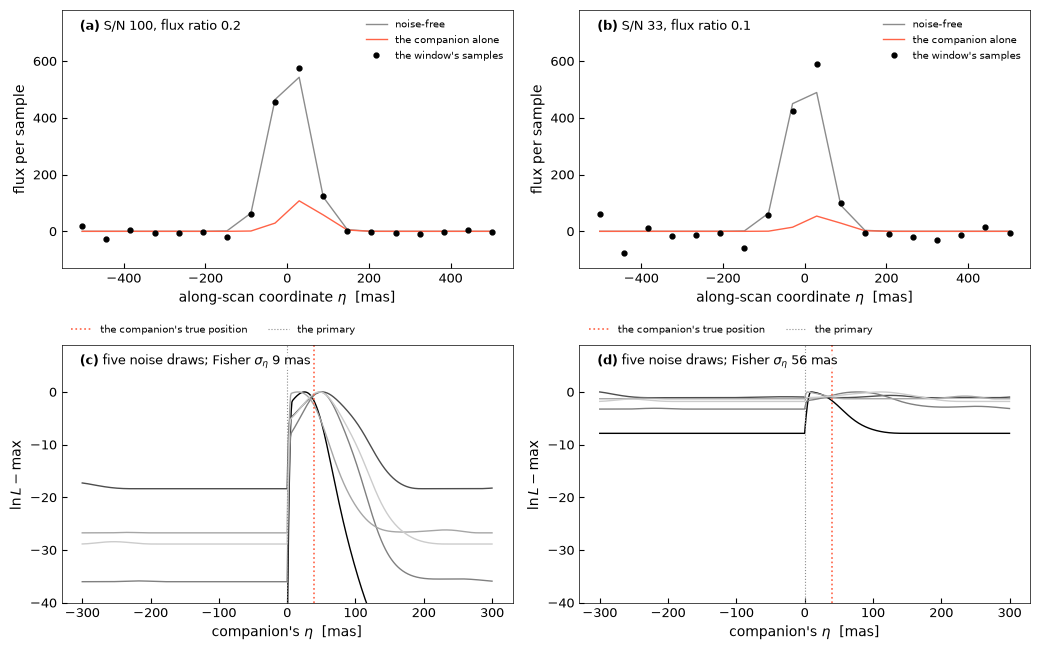

In [15]:
# Figure 1: one window of the pair at 40 mas, scanned along the pair axis, at the two signal-to-noise ratios
# (a, b), and the profiled log-likelihood of that window along eta for five noise draws (c, d). axes.T gives
# the columns, one case each; case_flux[1:] is the companion's flux alone
fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.6))
eta_pair = np.array([0.0, rho])                               # eta of the primary and of the companion [mas]
DRAW_COLORS = ("k", "0.3", "0.5", "0.65", "0.8")              # the color of each of the five noise draws
for col, labels, (q, noise_sigma, name) in zip(axes.T, ("ac", "bd"), CASES):
    # step 1, the top panel: the window's samples (one noise draw), the noise-free window, and the companion's
    # part of it. rng_noise: seed 3, the noise of this case's windows
    case_flux = np.array([1000.0, q * 1000.0])                # the fluxes of the primary and of the companion
    rng_noise = np.random.default_rng(3)
    first_window = sim.simulate_window(eta_pair, case_flux, inst, rng_noise, noise_sigma)
    noise_free = ins.render_window(eta_pair, case_flux, inst)
    companion_alone = ins.render_window(np.array([rho]), case_flux[1:], inst)
    col[0].plot(grid, noise_free, color="0.55", lw=1, label="noise-free")
    col[0].plot(grid, companion_alone, color=ACCENT, lw=1, label="the companion alone")
    col[0].plot(grid, first_window, "o", color="k", ms=3.5, label="the window's samples")
    col[0].set(xlabel=r"along-scan coordinate $\eta$  [mas]", ylabel="flux per sample", ylim=(-130, 780))
    col[0].legend(loc="upper right")
    letter(col[0], labels[0], name)

    # step 2, the bottom panel: the log-likelihood of five windows that differ in their noise only, each minus
    # its own maximum. The generator starts again at seed 3, so the first of the five windows is the window of
    # the top panel; k counts the draws
    rng_noise = np.random.default_rng(3)
    for k in range(5):
        window = sim.simulate_window(eta_pair, case_flux, inst, rng_noise, noise_sigma)
        loglike = window_loglike(window, pa, noise_sigma, etas)
        col[1].plot(etas, loglike - loglike.max(), lw=1, color=DRAW_COLORS[k])
    col[1].axvline(rho, color=ACCENT, ls=":", lw=1.2, label="the companion's true position")
    col[1].axvline(0.0, color="0.55", ls=":", lw=0.8, label="the primary")
    col[1].set(xlabel=r"companion's $\eta$  [mas]", ylabel=r"$\ln L - \max$", ylim=(-40, 9))
    col[1].legend(loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=2)
    # the Fisher error of the companion's position in this window (a formula); [0]: the one companion
    fisher_sigma = sigma_eta(eta_pair, case_flux, noise_sigma)[0]
    letter(col[1], labels[1], rf"five noise draws; Fisher $\sigma_\eta$ {fisher_sigma:.0f} mas")
plt.tight_layout()
plt.show()

## 2. The two images

*Paper: App. C.2, Eq. C.3 (the two images); a blended pair on them is not in the paper; it is here because the images stop at the LSF.*

**What they assume.** A resolution of about the LSF: the inverse Radon
transform returns the scene convolved with the LSF, faststack returns a
picture at the sample pitch with no LSF removed.

**What they return.** At 50 mas the inverse Radon transform shows one
elongated blob, the two blurred sources merged; faststack never shows the
companion at all, because in every window the strip that covers it also
holds the primary's light, so its pixels have no low samples to set r₀
from, and it sits on the edge of the primary's core (tutorial 2, section 6).

**The figure.** The two images of the pair at 50 mas (top) and of the control pair at 200 mas (bottom); the
plus signs mark the two sources.

**Do they warn.** No. A blended pair looks like one source.

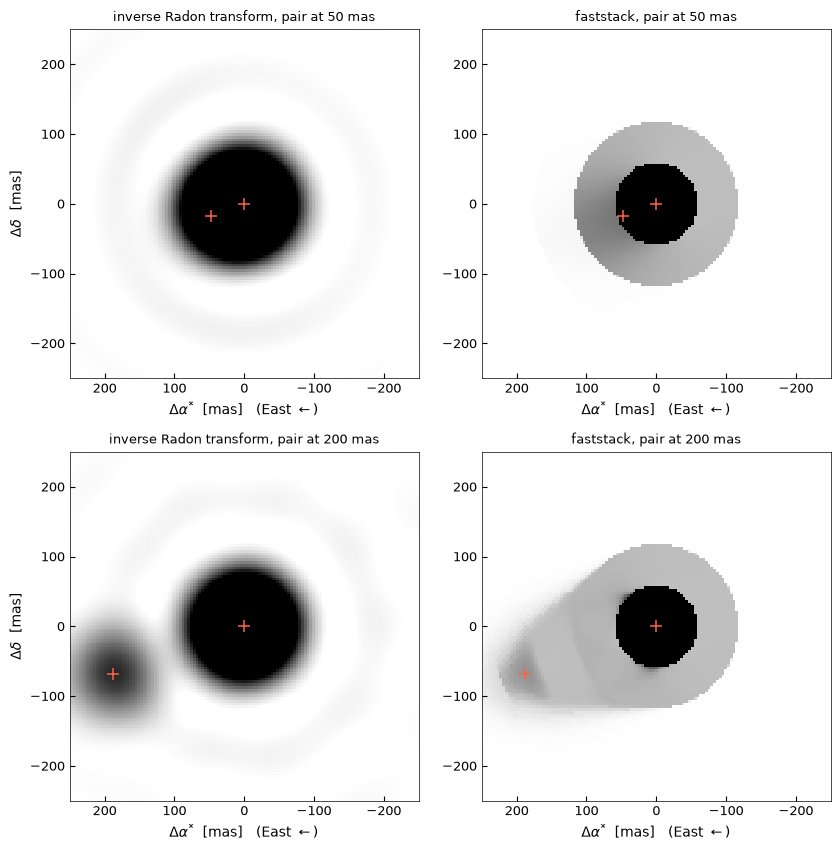

In [16]:
# Figure 2: the two images of the pair at 50 mas (top) and of the control pair at 200 mas (bottom), from
# noise-free windows. radon.faststack returns (image, variance, number of samples, axis); `_` drops the last
# three. `marks` stacks the primary at the origin on the companion: the two plus signs
fig, axes = plt.subplots(2, 2, figsize=(8.6, 8.6))
for row, separation in zip(axes, (50.0, 200.0)):
    companion = pair(separation)                              # the companion's (dra*, ddec) [mas]
    wins = windows_of(companion, EVEN)
    image, axis = radon.filtered_backprojection(EVEN, wins, inst, half, step)
    stack, _, _, _ = radon.faststack(EVEN, wins, inst, half, step)
    marks = np.vstack([[0.0, 0.0], companion])
    show(row[0], image, axis, f"inverse Radon transform, pair at {separation:.0f} mas", marks, vmax=0.02)
    show(row[1], stack, axis, f"faststack, pair at {separation:.0f} mas", marks, vmax=250)
    for ax in row:
        ax.set(xlim=(250, -250), ylim=(-250, 250))               # the inner 500 mas, east to the left
    row[0].set_ylabel(NORTH)
plt.tight_layout()
plt.show()

## 3. The map of detections

*Paper: Sect. 2.2 (the detections of one window); App. B.1 (their Fisher error). The fraction of window fits that leave the true basin is not in the paper; it is here because the map takes each detection as a line with a Gaussian width.*

**What it assumes.** That each window delivers the companion's along-scan
position with a Gaussian error bar: a line with a width.

**What it returns.** The lines it receives come from a per-window fit, and
that fit has the likelihood of section 1. The cell fits the companion's
position in one window 200 times from different noise. At S/N 100 every
fit lies within three Fisher errors and their scatter equals the bound. At
S/N 33 a quarter of the fits leave the true basin and land near the
primary's other wing or at the window's edge, hundreds of mas off, with the
companion's flux near zero; no error bar describes them. Fed to the map,
such a line adds one crest's worth of mass far from the crossing; the sum
tolerates a few of them while the true lines are many (tutorial 3,
section 5), and a per-window
reduction censors such windows, which is why the map is a sum and why
detections carry an outlier fraction.

**The figure.** The histogram of the 200 fitted positions minus the truth, for the two cases and for one
between them; the band is three Fisher errors either side of the truth.

**Does it warn.** The window fit does not; the fraction of its results
outside three error bars is the measurement of how often it is wrong.

                      case  Fisher σ_η [mas]  within 3σ  scatter of those [mas]  the others land at [mas]
   S/N 100, flux ratio 0.2               9.3       1.00                     9.3  none
    S/N 33, flux ratio 0.1              55.7       0.73                    67.6  -345 to 265, median -204
    S/N 50, flux ratio 0.1              37.1       0.78                    38.0  -345 to 265, median -120


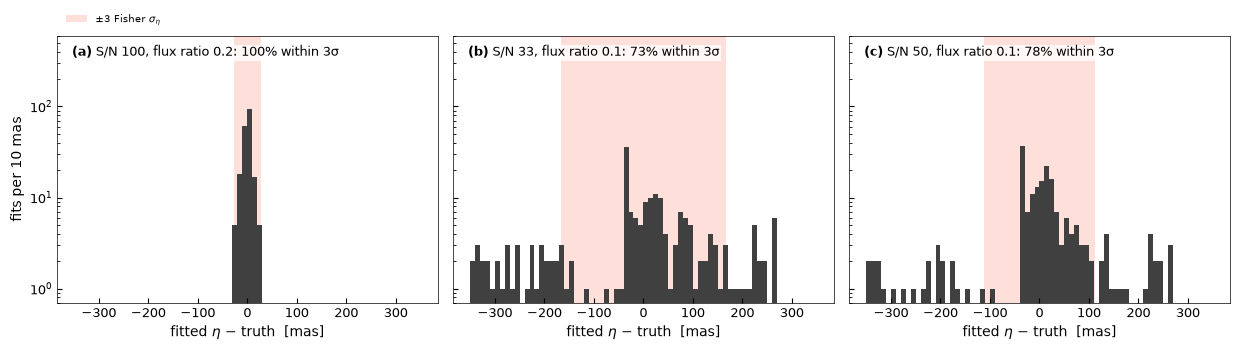

In [17]:
# Figure 3 and its table: 200 window fits per case at 40 mas along the scan: the fraction within 3 Fisher sigma,
# the scatter of those, and where the others land. sigma_eta(...)[0] is the error of the one companion; the
# mask `near` keeps the fits within 3 sigma of the truth, and ~near the others
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6), sharey=True)
print(f"{'case':>26s}  Fisher σ_η [mas]  within 3σ  scatter of those [mas]  the others land at [mas]")
N_FITS = 200                                                  # the number of windows fitted per case
THREE_CASES = CASES + ((0.1, 20.0, "S/N 50, flux ratio 0.1"),)    # the page's two cases, and a third at S/N 50
eta_pair = np.array([0.0, rho])                               # eta of the primary and of the companion [mas]
for ax, label, (q, noise_sigma, name) in zip(axes, "abc", THREE_CASES):
    # step 1, 200 windows that differ in their noise only, each fitted (a real fit: window_fit). rng_noise:
    # seed 7, the noise of this case's windows, drawn in the order of the fits
    case_flux = np.array([1000.0, q * 1000.0])                # the fluxes of the primary and of the companion
    rng_noise = np.random.default_rng(7)
    fitted_eta = []
    for _ in range(N_FITS):
        window = sim.simulate_window(eta_pair, case_flux, inst, rng_noise, noise_sigma)
        fitted_eta.append(window_fit(window, pa, noise_sigma))
    fitted_eta = np.array(fitted_eta)

    # step 2, truth: the fits against the companion's true position rho. fisher_sigma is the Fisher error of
    # the companion in one window (a formula); near: the mask of the fits within 3 of it; others: the rest
    fisher_sigma = sigma_eta(eta_pair, case_flux, noise_sigma)[0]
    near = np.abs(fitted_eta - rho) < 3 * fisher_sigma
    others = fitted_eta[~near] - rho
    if others.size:
        others_text = f"{others.min():.0f} to {others.max():.0f}, median {np.median(others):.0f}"
    else:
        others_text = "none"
    print(f"{name:>26s}  {fisher_sigma:16.1f}  {near.mean():9.2f}  {fitted_eta[near].std():22.1f}  " + others_text)

    # step 3, the panel: the histogram of fit minus truth in bins of 10 mas, over the band of 3 Fisher sigma
    ax.axvspan(-3 * fisher_sigma, 3 * fisher_sigma, color=ACCENT, alpha=0.2, lw=0, zorder=0,
               label=r"$\pm 3$ Fisher $\sigma_\eta$")
    ax.hist(fitted_eta - rho, bins=np.arange(-350, 351, 10), color="0.25")
    ax.set(xlabel=r"fitted $\eta$ $-$ truth  [mas]", yscale="log", ylim=(0.7, 600))
    letter(ax, label, f"{name}: {near.mean():.0%} within 3σ")
axes[0].set_ylabel("fits per 10 mas")
axes[0].legend(loc="lower left", bbox_to_anchor=(0.0, 1.0))
plt.tight_layout()
plt.show()

## 4. The joint fit

*Paper: Sect. 6.1, Fig. 5 and App. B.2 (the error of a position against the separation); Sect. 4.3, Eq. 18 (the joint fit). The fit from a wrong seed is not in the paper; it is here because the fit finds one maximum.*

**What it assumes.** One maximum of the profiled likelihood over the sky,
reached by Nelder–Mead from the seed; error bars from the curvature there.

**What it returns.** The inverse Fisher matrix, the Cramér–Rao bound, rises
smoothly as the pair closes, more than doubling from 2 FWHM to 0.3 FWHM,
and is finite everywhere: it knows nothing of basins. The fit itself finds
the basin it is seeded in. Seeded near the truth and at the mirror point on
the other side of the primary, on the same windows: at S/N 100 the wrong
basin's χ² is thousands above the right one and the fitted companion flux
there is zero, the fit having fallen back to one source; at S/N 33 the
wrong basin is still where the fit stays, about a hundred χ² units above
the right one, the companion's flux again zero.

**Does it warn.** Partly. The comparison of χ² between seeds does; one fit
alone does not, and the zero flux is the sign to look for.

flux ratio 0.2: Fisher sigma 0.76 mas at 2 FWHM, 1.07 at 0.5 FWHM, 1.70 at 0.3 FWHM
flux ratio 0.1: Fisher sigma 1.52 mas at 2 FWHM, 2.14 at 0.5 FWHM, 3.41 at 0.3 FWHM


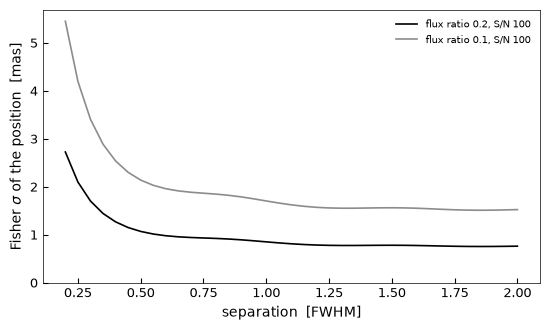

In [18]:
# Figure 4: the Fisher sigma of the companion's position against the separation, for two flux ratios, 80 windows
# and sigma 10. joint.joint_covariance(..., 2) returns (covariance, sigmas) of the two position parameters;
# [1] keeps the sigmas, and the plotted value is their root mean square. sigma_curve[-1] is the widest pair,
# 2 FWHM
rhos = np.linspace(20.0, 200.0, 37)                           # the separations [mas], 5 mas apart
fig, ax = plt.subplots(figsize=(5.6, 3.4))
for q, color in ((0.2, "k"), (0.1, "0.55")):
    case_flux = np.array([1000.0, q * 1000.0])                # the fluxes of the primary and of the companion
    # the Fisher error at each separation (a formula at the truth: no windows, no fit and no noise draw); 10.0
    # is the noise sigma of one sample
    sigma_curve = []
    for separation in rhos:
        fisher = joint.joint_fisher(pair(separation), case_flux, EVEN, inst, 10.0)
        sigma_position = joint.joint_covariance(fisher, 2)[1]
        sigma_curve.append(np.sqrt(np.mean(sigma_position ** 2)))
    sigma_curve = np.array(sigma_curve)
    ax.plot(rhos / FWHM, sigma_curve, color=color, lw=1.2, label=f"flux ratio {q}, S/N 100")
    # the entries of the curve nearest to 50 mas and to 30 mas
    at_50_mas = sigma_curve[np.argmin(np.abs(rhos - 50))]
    at_30_mas = sigma_curve[np.argmin(np.abs(rhos - 30))]
    print(f"flux ratio {q}: Fisher sigma {sigma_curve[-1]:.2f} mas at 2 FWHM, {at_50_mas:.2f} at 0.5 FWHM, "
          f"{at_30_mas:.2f} at 0.3 FWHM")
ax.set(xlabel="separation  [FWHM]", ylabel=r"Fisher $\sigma$ of the position  [mas]", ylim=(0, None))
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [19]:
# the joint fit of the pair at 50 mas from two seeds, near the truth and at the mirror point -theta, on the same
# windows, at the two signal-to-noise ratios
print(f"\n{'case':>26s}  {'seed':>16s}   fit − truth [mas]   chi2 − chi2(near)   fitted fluxes")
for q, noise_sigma, name in CASES:
    # step 1, the 80 noisy windows of the pair at this case's flux ratio and noise. rng_noise: seed 1, the noise
    # of this case's windows, drawn window by window
    case_flux = np.array([1000.0, q * 1000.0])                # the fluxes of the primary and of the companion
    rng_noise = np.random.default_rng(1)
    wins = []
    for eta_j in joint.scene_positions_al(theta, EVEN):
        wins.append(sim.simulate_window(eta_j, case_flux, inst, rng_noise, noise_sigma))
    wins = np.array(wins)

    # step 2, two fits of the same windows: started 10 mas from the truth, and started at the mirror point
    fit_near = joint.fit_joint(wins, EVEN, theta + [8.0, -6.0], inst, noise_sigma)
    fit_mirror = joint.fit_joint(wins, EVEN, -theta, inst, noise_sigma)
    for seed, fit in (("near the truth", fit_near), ("the mirror point", fit_mirror)):
        error = fit["theta"] - theta                          # truth: fit minus the true (dra*, ddec) [mas]
        chi2_above_near = fit["chi2"] - fit_near["chi2"]
        print(f"{name:>26s}  {seed:>16s}   ({error[0]:6.1f}, {error[1]:6.1f})   {chi2_above_near:14.0f}      "
              f"{fit['flux'][0]:.0f}, {fit['flux'][1]:.0f}")


                      case              seed   fit − truth [mas]   chi2 − chi2(near)   fitted fluxes
   S/N 100, flux ratio 0.2    near the truth   (  -1.3,    1.5)                0      990, 208
   S/N 100, flux ratio 0.2  the mirror point   ( -94.0,   34.2)             3498      1170, 0
    S/N 33, flux ratio 0.1    near the truth   (  -9.2,    9.1)                0      962, 132
    S/N 33, flux ratio 0.1  the mirror point   ( -94.0,   34.2)              110      1082, 0


## Summary

| atom | effect in this case | alarm | remedy |
|---|---|---|---|
| inverse Radon transform | one merged blob at 0.5 FWHM | none | none; the images stop at the LSF |
| faststack | the companion never leaves the primary's core | none | none |
| map of detections | receives lines from a window fit that, at S/N 33, is hundreds of mas off a quarter of the time | the window fit does not warn; the fraction outside 3σ measures it | censor such windows in the per-window reduction; keep the map a sum |
| joint fit | the bound rises smoothly and sees no basin; the fit stays in the basin it is seeded in, with zero companion flux in the wrong one | the χ² difference between seeds; a zero flux | seeds from the map's peaks, compared by χ² |

## What this establishes

- The Fisher bound rises smoothly as the pair closes, more than doubling at
  0.3 FWHM; it is the curvature at the truth and sees no other basin.
- Below a FWHM and at low signal-to-noise the likelihood of one window has
  several basins: the other wing of the primary and the window's edges. A
  fraction of window fits lands there, hundreds of mas off, and no error bar
  describes them.
- The joint fit finds the basin it is seeded in. The wrong basin fits the
  companion with zero flux; at high S/N its χ² gives it away by thousands, at
  low S/N by about a hundred. Seeds are compared by χ², and the map provides
  them.